In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier

In [2]:
df = pd.read_csv("./drug200.csv")
df

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,drugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,drugY
...,...,...,...,...,...,...
195,56,F,LOW,HIGH,11.567,drugC
196,16,M,LOW,HIGH,12.006,drugC
197,52,M,NORMAL,HIGH,9.894,drugX
198,23,M,NORMAL,NORMAL,14.020,drugX


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [4]:
df.isnull().sum()

Age            0
Sex            0
BP             0
Cholesterol    0
Na_to_K        0
Drug           0
dtype: int64

In [5]:
df.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


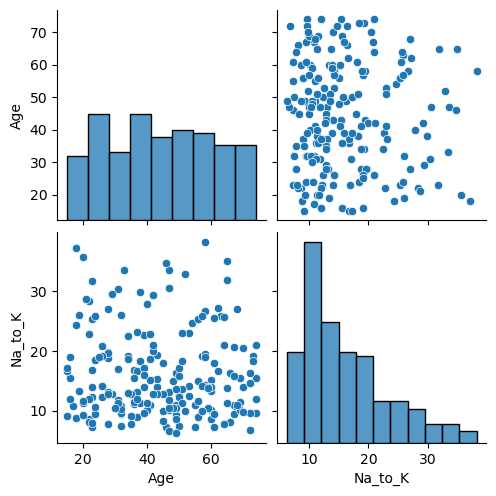

In [6]:
sns.pairplot(df)
plt.show()

## Label Encoding

In [7]:
df["BP"] = df["BP"].map({"LOW":0,"NORMAL":1, "HIGH":2})
df["Cholesterol"] = df["Cholesterol"].map({"NORMAL":0, "HIGH":1})
df["Drug"] = df["Drug"].map({'drugA':1, 'drugB':2, 'drugC':3, 'drugX':4, 'drugY':5})

In [8]:
df.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,2,1,25.355,5
1,47,M,0,1,13.093,3
2,47,M,0,1,10.114,3
3,28,F,1,1,7.798,4
4,61,F,0,1,18.043,5


In [45]:
x = df[['Na_to_K', 'Cholesterol', 'Drug']]
y = df["BP"]  

In [46]:
from sklearn.feature_selection import SelectKBest,f_classif

In [47]:
select = SelectKBest(f_classif, k = 3)
x_select = select.fit_transform(x,y)
column_name = x.columns[select.get_support()]
column_name

Index(['Na_to_K', 'Cholesterol', 'Drug'], dtype='object')

In [48]:
from sklearn.model_selection import train_test_split

In [49]:
xtrain, xtest, ytrain, ytest = train_test_split(x,y, test_size = 0.2, random_state = 42)
xtrain.shape, xtest.shape, ytrain.shape, ytest.shape

((160, 3), (40, 3), (160,), (40,))

## Instantiating the model

In [50]:
rfc = RandomForestClassifier()
model = rfc.fit(xtrain,ytrain)
model

RandomForestClassifier()

## Prediction

In [51]:
y_pred = model.predict(xtest)
y_pred

array([0, 2, 0, 0, 0, 2, 2, 1, 2, 1, 2, 0, 2, 2, 2, 2, 2, 1, 0, 2, 2, 0,
       1, 2, 0, 0, 0, 0, 2, 0, 2, 0, 0, 2, 2, 2, 0, 2, 0, 2])

In [61]:
# predicting the blood pressure using the value for Na_to_k,Cholesterol,Drug value

In [54]:
pred1 = model.predict([[25, 1, 5]])
pred1

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([2])

In [55]:
pred2 = model.predict([[10, 1, 43]])
pred2

C:\Users\USER\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


array([1])

## Model Evaluation

In [56]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [57]:
acc = accuracy_score(ytest,y_pred)
acc

0.725

In [58]:
Cm = confusion_matrix(ytest,y_pred)
Cm

array([[12,  1,  4],
       [ 3,  3,  2],
       [ 1,  0, 14]])

In [59]:
cr = classification_report(ytest,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.75      0.71      0.73        17
           1       0.75      0.38      0.50         8
           2       0.70      0.93      0.80        15

    accuracy                           0.72        40
   macro avg       0.73      0.67      0.68        40
weighted avg       0.73      0.72      0.71        40



In [60]:
df["Drug"].unique()

array([5, 3, 4, 1, 2])